# FFT benchmark across machines

This notebook compares `numpy.fft.fft`, `scipy.fft.fft`, and `rustfft_numpy.fft` for complex64 inputs. It includes single transforms and a batch of 526 32,768-point transforms representing the frames in a 90-second, 96 kHz signal with 50% overlap.

The benchmark measures the complete function call, including Python wrapper overhead and output allocation. The batched measurement transforms already-extracted frames; it excludes framing and Hann windowing. Points show the median of five samples; error bars show the first to third quartile.

Run `python benchmarks/benchmark_fft.py` on each machine. Each run saves a host-specific CSV containing CPU, OS, architecture, and library versions. Copy the resulting `results-*.csv` files into this directory to compare multiple machines here. See [README.md](../README.md) for native setup instructions on macOS Apple Silicon and Linux.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import rustfft_numpy as rustfft_np

ROOT = Path.cwd()
if list(ROOT.glob('results-*.csv')):
    RESULTS_DIR = ROOT
elif list((ROOT / 'benchmarks').glob('results-*.csv')):
    RESULTS_DIR = ROOT / 'benchmarks'
else:
    RESULTS_DIR = ROOT / 'benchmarks'
result_files = sorted(RESULTS_DIR.glob('results-*.csv'))
if not result_files:
    raise FileNotFoundError(f'No host result files found in {RESULTS_DIR}; run benchmarks/benchmark_fft.py first.')
df = pd.concat([pd.read_csv(path) for path in result_files], ignore_index=True)
print(f'Notebook runtime: Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | {platform.machine()}')
print(f'Loaded {len(result_files)} machine result file(s):')
for path in result_files:
    print(f'  {path.name}')
print(f'Output dtype — NumPy: {np.fft.fft(np.ones(8, dtype=np.complex64)).dtype}; rustfft_numpy: {rustfft_np.fft(np.ones(8, dtype=np.complex64)).dtype}')
df[['machine_id', 'cpu', 'os', 'numpy', 'scipy']].drop_duplicates()

Notebook runtime: Python 3.12.13 | NumPy 2.5.4 | SciPy 1.18.1 | aarch64
Loaded 1 machine result file(s):
  results-linux-aarch64-thinkstationpgx-3d28.csv
Output dtype — NumPy: complex64; rustfft_numpy: complex64


,machine_id,cpu,os,numpy,scipy
0,linux-aarch64-thinkstationpgx-3d28,Cortex-X925 / Cortex-A725,Linux-6.17.0-1021-nvidia-aarch64-with-glibc2.43,2.5.4,1.18.1


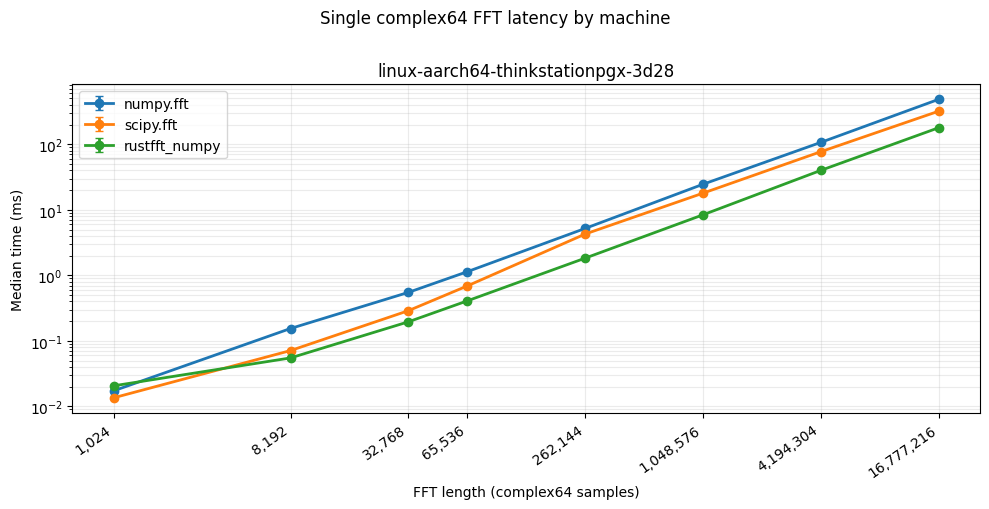

In [2]:
single = df[df.workload == 'single_fft'].copy()
machines = sorted(single.machine_id.unique())
fig, axes = plt.subplots(len(machines), 1, figsize=(10, 5 * len(machines)), squeeze=False, sharex=True)
for ax, machine in zip(axes[:, 0], machines):
    subset = single[single.machine_id == machine]
    for name, group in subset.groupby('implementation', sort=False):
        group = group.sort_values('n')
        yerr = np.vstack([group.median_ms - group.q1_ms, group.q3_ms - group.median_ms])
        ax.errorbar(group.n, group.median_ms, yerr=yerr, marker='o', capsize=3, linewidth=2, label=name)
    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_ylabel('Median time (ms)')
    ax.set_title(machine)
    ax.grid(True, which='both', alpha=.25)
    ax.legend()
axes[-1, 0].set_xticks(sorted(single.n.unique()), [f'{int(n):,}' for n in sorted(single.n.unique())], rotation=35, ha='right')
axes[-1, 0].set_xlabel('FFT length (complex64 samples)')
fig.suptitle('Single complex64 FFT latency by machine', y=1.01)
fig.tight_layout()
plt.show()

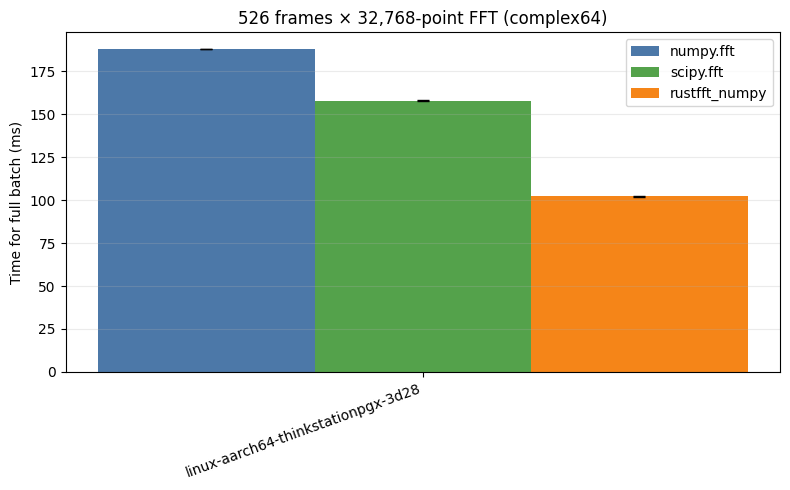

Speed ratios relative to NumPy on each machine:
linux-aarch64-thinkstationpgx-3d28
  scipy.fft: 1.19× faster
  rustfft_numpy: 1.84× faster


In [3]:
batch = df[df.workload == 'stft_frames_fft_only'].copy()
implementations = ['numpy.fft', 'scipy.fft', 'rustfft_numpy']
machines = sorted(batch.machine_id.unique())
colors = {'numpy.fft': '#4c78a8', 'scipy.fft': '#54a24b', 'rustfft_numpy': '#f58518'}
width = 0.23
fig, ax = plt.subplots(figsize=(max(8, 3 * len(machines)), 5))
centers = np.arange(len(machines))
for j, implementation in enumerate(implementations):
    vals, lows, highs = [], [], []
    for machine in machines:
        match = batch[(batch.machine_id == machine) & (batch.implementation == implementation)]
        vals.append(float(match.median_ms.iloc[0]) if len(match) else np.nan)
        lows.append(float(match.q1_ms.iloc[0]) if len(match) else np.nan)
        highs.append(float(match.q3_ms.iloc[0]) if len(match) else np.nan)
    vals = np.asarray(vals)
    yerr = np.vstack([vals - np.asarray(lows), np.asarray(highs) - vals])
    pos = centers + (j - 1) * width
    ax.bar(pos, vals, width=width, color=colors[implementation], label=implementation)
    ax.errorbar(pos, vals, yerr=yerr, fmt='none', ecolor='black', capsize=4)
ax.set_xticks(centers, machines, rotation=20, ha='right')
ax.set_ylabel('Time for full batch (ms)')
ax.set_title('526 frames × 32,768-point FFT (complex64)')
ax.grid(axis='y', alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()

print('Speed ratios relative to NumPy on each machine:')
for machine in machines:
    table = batch[batch.machine_id == machine].set_index('implementation').median_ms
    print(machine)
    for implementation in ['scipy.fft', 'rustfft_numpy']:
        if 'numpy.fft' in table and implementation in table:
            print(f'  {implementation}: {table["numpy.fft"] / table[implementation]:.2f}× faster')

## Reading cross-machine results

Compare implementations within a machine first. Different CPU generations, power modes, compiler versions, and FFT library builds affect timings. The CSVs record host and software metadata to make those conditions visible. Rust extensions should be built natively on each machine with `maturin develop --release`; do not copy the compiled extension binary between operating systems or architectures.

SciPy 1.18 uses its `ducc0.fft` backend by default. The benchmark compares complete Python calls and output allocation rather than isolated FFT kernels.